# Claim severity in the 1977 Swedish motor tariff

The committee that built the Swedish third-party tariff had one rating structure for every company, and it had to say what a claim costs once it occurs. Frequency is a different object. This page is the severity component: kronor per claim, in a cell defined by annual kilometres, geographical zone, no-claims bonus, and make.

The file is the 1977 portfolio table, 2,182 cells, from the CSV circulated with Frees, *Regression Modeling with Actuarial and Financial Applications*: `https://instruction.bus.wisc.edu/jfrees/jfreesbooks/Regression%20Modeling/BookWebDec2010/CSVData/SwedishMotorInsurance.csv`. Hallin and Ingenbleek (1983) describe the portfolio; the printed table is the StatLib (statistical data and software archive) extract, also hosted by OzDASL (Australasian Data and Story Library). `Payment` is the cell total in kronor, `Claims` is the count, and `Insured` is exposure in policy-years. Cells with no claims have no severity and are dropped. Make 4 is the Volkswagen 1200. The other makes were masked.

The decision is which distribution to book as the severity component of the pure premium (the expected claim cost per policy, frequency times severity). A gamma GLM with a log link is the usual tariff model. A lognormal, fit as a Gaussian on log severity, and a Gaussian on the kronor amount are the alternatives. The boosted models use the same indicators for the rating factors (the tariff variables that set the premium). Steps are chosen on held-out cells, stratified by zone. The score weights cells by claim count, because a one-claim cell and a three-thousand-claim cell are not the same premium.


:::{admonition} What this study estimates
:class: dropdown

| | |
|---|---|
| **Target** | kronor paid per claim in a tariff cell |
| **Observed response** | `Payment / Claims`, for cells with at least one claim |
| **Estimand** | claim-weighted mean absolute error of the mean severity, and the claim-weighted mean negative log density |
| **Units** | 1977 Swedish kronor per claim; nats per claim |
| **Sampling unit** | one row is one 1977 tariff cell; its severity mean is weighted by its claim count |
| **Dependence** | Cells share tariff factors and zones; splitting is by cell, without a geographic cluster adjustment. |
| **Split and tuning** | cells, stratified by zone; 20% choose boosting steps, 20% held out, refit on the rest |
| **Information** | kilometres class, zone, bonus class, make. Reference levels are under 1,000 km, rural southern Sweden (zone 4), bonus class 1, and make 1 |
| **Uncertainty** | fitted predictive distributions are scored; no resampling confidence intervals for score differences are reported |
| **Claim type** | predictive comparisons conditional on the recorded covariates; no causal effects are estimated |
| **What this does not estimate** | claim frequency, a claim-level severity sample (only the cell total is observed), or a tariff for a later year |

The weighted log score treats every claim in a cell as if it cost the cell average. That is the likelihood this table can support. It is not the likelihood of 113,000 individual claims.

:::


In [1]:
import warnings
from pathlib import Path

import altair as alt
import numpy as np
import polars as pl
import statsmodels.api as sm
import statsmodels.formula.api as smf
from IPython.display import display
from scipy import stats
from sklearn.linear_model import GammaRegressor

import mboostrs as mb

csv_path = Path("swedish_motor_1977.csv")
if not csv_path.exists():
    csv_path = Path("docs/book/case_studies/swedish_motor_1977.csv")
raw = pl.read_csv(csv_path, comment_prefix="#")
dropped = int((raw["Claims"] == 0).sum())
base = raw.filter(pl.col("Claims") > 0).with_columns(
    (pl.col("Payment") / pl.col("Claims")).alias("severity"),
    pl.col("Claims").cast(pl.Float64),
    (pl.col("Payment") / pl.col("Claims")).log().alias("log_severity"),
)
# Indicators, so glmboost does not have to encode a factor. Reference levels
# are the ones named in the header.
reference = {"Kilometres": 1, "Zone": 4, "Bonus": 1, "Make": 1}
prefix = {"Kilometres": "km", "Zone": "zone", "Bonus": "bonus", "Make": "make"}
frame = base
for col, ref in reference.items():
    levels = sorted(int(v) for v in frame[col].unique().to_list() if int(v) != ref)
    frame = frame.with_columns(
        [(pl.col(col) == lev).cast(pl.Float64).alias(f"{prefix[col]}_{lev}") for lev in levels]
    )
predictors = [c for c in frame.columns if c.startswith(("km_", "zone_", "bonus_", "make_"))]
formula = "severity ~ " + " + ".join(predictors)
log_formula = "log_severity ~ " + " + ".join(predictors)

rng = np.random.default_rng(20261004)
indexed = frame.with_row_index("i")
parts = []
for zone in sorted(int(z) for z in frame["Zone"].unique().to_list()):
    ids = indexed.filter(pl.col("Zone") == zone)["i"].to_numpy().copy()
    rng.shuffle(ids)
    n = len(ids)
    n_test = int(round(0.20 * n))
    n_valid = int(round(0.20 * n))
    parts.append((ids[n_test + n_valid :], ids[n_test : n_test + n_valid], ids[:n_test]))
train_ids = np.concatenate([p[0] for p in parts])
valid_ids = np.concatenate([p[1] for p in parts])
test_ids = np.concatenate([p[2] for p in parts])
train = frame[train_ids.tolist()]
valid = frame[valid_ids.tolist()]
fit_rows = frame[np.concatenate([train_ids, valid_ids]).tolist()]
test = frame[test_ids.tolist()]
y_test = test["severity"].to_numpy()
w_test = test["Claims"].to_numpy()
print(
    f"{raw.height} cells, {dropped} with no claims dropped, {frame.height} with a severity, "
    f"{train.height} to fit the path, {valid.height} to choose steps, {fit_rows.height} refit, "
    f"{test.height} held out ({int(w_test.sum())} claims)"
)


2182 cells, 385 with no claims dropped, 1797 with a severity, 1077 to fit the path, 360 to choose steps, 1437 refit, 360 held out (28609 claims)


In [2]:
def columns_of(data):
    return {name: data[name].to_numpy() for name in data.columns}


def weighted_mean(values, weights):
    values = np.asarray(values, dtype=float)
    weights = np.asarray(weights, dtype=float)
    return float(np.sum(values * weights) / np.sum(weights))


def gamma_nll(y, mu, shape, weights):
    mu = np.clip(np.asarray(mu, dtype=float), 1e-8, None)
    return weighted_mean(-stats.gamma.logpdf(y, a=shape, scale=mu / shape), weights)


def lognormal_nll(y, mu_log, sd, weights):
    return weighted_mean(-stats.lognorm.logpdf(y, s=max(sd, 1e-8), scale=np.exp(mu_log)), weights)


def gaussian_nll(y, mu, sd, weights):
    return weighted_mean(-stats.norm.logpdf(y, mu, max(sd, 1e-8)), weights)


def weighted_sd(y, mu, weights):
    resid = np.asarray(y, dtype=float) - np.asarray(mu, dtype=float)
    return float(np.sqrt(np.sum(weights * resid**2) / np.sum(weights)))


fit_w = fit_rows["Claims"].to_numpy()
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    gamma = smf.glm(
        formula,
        columns_of(fit_rows),
        family=sm.families.Gamma(sm.families.links.Log()),
        freq_weights=fit_w,
    ).fit()
    log_wls = smf.wls(log_formula, columns_of(fit_rows), weights=fit_w).fit()
    gauss_wls = smf.wls(formula, columns_of(fit_rows), weights=fit_w).fit()
    sklearn_gamma = GammaRegressor(alpha=0.0, max_iter=500)
    sklearn_gamma.fit(fit_rows.select(predictors).to_numpy(), fit_rows["severity"].to_numpy(), sample_weight=fit_w)

gamma_mu = np.asarray(gamma.predict(columns_of(test)), dtype=float)
gamma_shape = 1.0 / float(gamma.scale)
log_mu = np.asarray(log_wls.predict(columns_of(test)), dtype=float)
log_sd = weighted_sd(fit_rows["log_severity"].to_numpy(), log_wls.fittedvalues, fit_w)
log_mean = np.exp(log_mu + 0.5 * log_sd**2)
gauss_mu = np.asarray(gauss_wls.predict(columns_of(test)), dtype=float)
gauss_sd = weighted_sd(fit_rows["severity"].to_numpy(), gauss_wls.fittedvalues, fit_w)
sklearn_mu = np.asarray(sklearn_gamma.predict(test.select(predictors).to_numpy()), dtype=float)
train_sk = np.asarray(sklearn_gamma.predict(fit_rows.select(predictors).to_numpy()), dtype=float)
sklearn_shape = 1.0 / weighted_mean(((fit_rows["severity"].to_numpy() - train_sk) / train_sk) ** 2, fit_w)
zone1 = float(gamma.params["zone_1"])


In [3]:
def choose_mstop(kind, cap, nu):
    weights = train["Claims"].to_numpy()
    y_valid = valid["severity"].to_numpy()
    w_valid = valid["Claims"].to_numpy()
    if kind == "gamma":
        path = mb.glmboost(
            formula, train, family=mb.GammaReg(), weights=weights, weight_policy="raw",
            control=mb.boost_control(cap, nu),
        )
    elif kind == "lognormal":
        path = mb.glmboost(
            log_formula, train, family=mb.Gaussian(), weights=weights, weight_policy="raw",
            control=mb.boost_control(cap, nu),
        )
    else:
        path = mb.glmboost(
            formula, train, family=mb.Gaussian(), weights=weights, weight_policy="raw",
            control=mb.boost_control(cap, nu),
        )
    best_step, best_score = None, np.inf
    for step in range(20, cap + 1, 20):
        tuned = path.with_mstop(step)
        if kind == "gamma":
            mu = np.asarray(tuned.predict(valid, type="response"), dtype=float).ravel()
            shape = float(np.asarray(tuned.nuisance()).ravel()[0])
            score = gamma_nll(y_valid, mu, shape, w_valid)
        elif kind == "lognormal":
            mu_log = np.asarray(tuned.predict(valid, type="response"), dtype=float).ravel()
            train_mu = np.asarray(tuned.predict(train, type="response"), dtype=float).ravel()
            sd = weighted_sd(train["log_severity"].to_numpy(), train_mu, weights)
            score = lognormal_nll(y_valid, mu_log, sd, w_valid)
        else:
            mu = np.asarray(tuned.predict(valid, type="response"), dtype=float).ravel()
            train_mu = np.asarray(tuned.predict(train, type="response"), dtype=float).ravel()
            sd = weighted_sd(train["severity"].to_numpy(), train_mu, weights)
            score = gaussian_nll(y_valid, mu, sd, w_valid)
        if score < best_score:
            best_step, best_score = step, score
    return best_step, best_score, best_step == cap


# nu=0.1 on the claim-weighted gamma collapses the fitted means after a few
# steps and then stops. 0.02 keeps the training risk descending. The other two
# families use the package default.
jobs = [
    ("mboostrs glmboost GammaReg", "gamma", 600, 0.02),
    ("mboostrs glmboost lognormal", "lognormal", 800, 0.1),
    ("mboostrs glmboost Gaussian", "gaussian", 800, 0.1),
]
boosted = {}
fit_weights = fit_rows["Claims"].to_numpy()
for label, kind, cap, nu in jobs:
    step, score, at_cap = choose_mstop(kind, cap, nu)
    if kind == "gamma":
        fitted = mb.glmboost(
            formula, fit_rows, family=mb.GammaReg(), weights=fit_weights, weight_policy="raw",
            control=mb.boost_control(step, nu),
        )
        pred = fitted.predict(test, type="response")
    elif kind == "lognormal":
        fitted = mb.glmboost(
            log_formula, fit_rows, family=mb.Gaussian(), weights=fit_weights, weight_policy="raw",
            control=mb.boost_control(step, nu),
        )
        pred = fitted.predict(test, type="response")
    else:
        fitted = mb.glmboost(
            formula, fit_rows, family=mb.Gaussian(), weights=fit_weights, weight_policy="raw",
            control=mb.boost_control(step, nu),
        )
        pred = fitted.predict(test, type="response")
    boosted[label] = {"mstop": step, "validation": score, "at_cap": at_cap, "fit": fitted, "pred": pred, "kind": kind}


In [4]:
rows = []


def add(method, mu, nll, mstop=None, at_cap=None, note=""):
    mu = np.asarray(mu, dtype=float).ravel()
    rows.append({
        "method": method,
        "mae": weighted_mean(np.abs(mu - y_test), w_test),
        "nll": nll,
        "mstop": mstop,
        "at_cap": at_cap,
        "note": note,
    })


add(
    "statsmodels Gamma GLM",
    gamma_mu,
    gamma_nll(y_test, gamma_mu, gamma_shape, w_test),
    note=f"shape {gamma_shape:.2f}",
)
add(
    "statsmodels WLS lognormal",
    log_mean,
    lognormal_nll(y_test, log_mu, log_sd, w_test),
    note=f"log sd {log_sd:.3f}",
)
add(
    "statsmodels WLS Gaussian",
    gauss_mu,
    gaussian_nll(y_test, gauss_mu, gauss_sd, w_test),
    note=f"residual sd {gauss_sd:.0f}; negative means {float((gauss_mu < 0).mean()):.3f}",
)
add(
    "sklearn GammaRegressor",
    sklearn_mu,
    gamma_nll(y_test, sklearn_mu, sklearn_shape, w_test),
    note=f"Pearson shape {sklearn_shape:.2f}",
)
for label, item in boosted.items():
    kind, pred, fitted = item["kind"], item["pred"], item["fit"]
    if kind == "gamma":
        mu = np.asarray(pred, dtype=float).ravel()
        shape = float(np.asarray(fitted.nuisance()).ravel()[0])
        add(label, mu, gamma_nll(y_test, mu, shape, w_test), item["mstop"], item["at_cap"],
            note=f"shape {shape:.2f}")
        gamma_boost_shape = shape
    elif kind == "lognormal":
        mu_log = np.asarray(pred, dtype=float).ravel()
        train_mu = np.asarray(fitted.predict(fit_rows, type="response"), dtype=float).ravel()
        sd = weighted_sd(fit_rows["log_severity"].to_numpy(), train_mu, fit_weights)
        add(label, np.exp(mu_log + 0.5 * sd**2), lognormal_nll(y_test, mu_log, sd, w_test),
            item["mstop"], item["at_cap"], note=f"log sd {sd:.3f}")
        log_boost_sd = sd
    else:
        mu = np.asarray(pred, dtype=float).ravel()
        train_mu = np.asarray(fitted.predict(fit_rows, type="response"), dtype=float).ravel()
        sd = weighted_sd(fit_rows["severity"].to_numpy(), train_mu, fit_weights)
        add(label, mu, gaussian_nll(y_test, mu, sd, w_test), item["mstop"], item["at_cap"],
            note=f"residual sd {sd:.0f}")

summary = pl.DataFrame(rows).sort("nll")
display(summary)


method,mae,nll,mstop,at_cap,note
str,f64,f64,i64,bool,str
"""mboostrs glmboost GammaReg""",450.673824,8.190796,500,false,"""shape 23.23"""
"""mboostrs glmboost lognormal""",543.642083,8.207628,800,true,"""log sd 0.211"""
"""statsmodels WLS lognormal""",549.496819,8.211028,null,null,"""log sd 0.210"""
"""sklearn GammaRegressor""",451.547991,8.220618,null,null,"""Pearson shape 19.58"""
"""statsmodels Gamma GLM""",451.745165,8.221238,null,null,"""shape 19.53"""
"""statsmodels WLS Gaussian""",445.479211,8.275346,null,null,"""residual sd 1125; negative mea…"
"""mboostrs glmboost Gaussian""",435.671746,8.275767,780,false,"""residual sd 1127"""


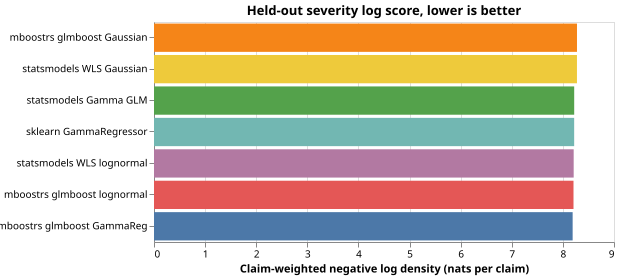

In [5]:
alt.Chart(summary).mark_bar().encode(
    x=alt.X("nll:Q", title="Claim-weighted negative log density (nats per claim)", scale=alt.Scale(zero=False)),
    y=alt.Y("method:N", sort="-x", title=None),
    color=alt.Color("method:N", legend=None),
).properties(
    width=460,
    height=220,
    title="Held-out severity log score, lower is better",
)


## Results and interpretation

Book the gamma mean as the severity component of the pure premium. On the held-out cells the gamma GLM is off by {eval}`f"{float(summary.filter(pl.col('method')=='statsmodels Gamma GLM')['mae'][0]):.0f}"` kronor per claim, and `sklearn.linear_model.GammaRegressor` with no penalty is within a krona of it. The boosted gamma, step size 0.02 rather than the package default, has absolute error {eval}`f"{float(summary.filter(pl.col('method')=='mboostrs glmboost GammaReg')['mae'][0]):.0f}"` and the best log score in the table, {eval}`f"{float(summary.filter(pl.col('method')=='mboostrs glmboost GammaReg')['nll'][0]):.3f}"` nats per claim. The GLM shape is {eval}`f"{gamma_shape:.1f}"`.

The Gaussian boost has the smallest absolute error, {eval}`f"{float(summary.filter(pl.col('method')=='mboostrs glmboost Gaussian')['mae'][0]):.0f}"` kronor, about {eval}`f"{float(summary.filter(pl.col('method')=='statsmodels Gamma GLM')['mae'][0] - summary.filter(pl.col('method')=='mboostrs glmboost Gaussian')['mae'][0]):.0f}"` better than the gamma GLM. Its log score is {eval}`f"{float(summary.filter(pl.col('method')=='mboostrs glmboost Gaussian')['nll'][0]):.3f}"`, with the weighted Gaussian at {eval}`f"{float(summary.filter(pl.col('method')=='statsmodels WLS Gaussian')['nll'][0]):.3f}"`. That gap is the distribution, not the point tariff. A normal with residual sd about 1,100 kronor is not the severity to publish. The share of negative Gaussian means on this holdout is {eval}`f"{float((gauss_mu < 0).mean()):.1%}"`.

The lognormal means are {eval}`f"{float(summary.filter(pl.col('method')=='mboostrs glmboost lognormal')['mae'][0]):.0f}"` and {eval}`f"{float(summary.filter(pl.col('method')=='statsmodels WLS lognormal')['mae'][0]):.0f}"` kronor off. Their log scores, {eval}`f"{float(summary.filter(pl.col('method')=='mboostrs glmboost lognormal')['nll'][0]):.3f}"` and {eval}`f"{float(summary.filter(pl.col('method')=='statsmodels WLS lognormal')['nll'][0]):.3f}"`, beat the gamma GLM by about a hundredth of a nat and do not beat the gamma boost. Do not load `exp(mu + sd^2 / 2)` into the pure premium. `exp(mu)` is the median, not the expected kronor per claim. The log-severity boost is still at its 800-step cap, and the fully converged weighted least squares fit is no better as a mean, so the cap is not the reason the lognormal premium is high.

Zone 1 (Stockholm, Göteborg, Malmö and surroundings) has gamma log-mean coefficient {eval}`f"{zone1:.3f}"`, {eval}`f"{100 * (np.exp(zone1) - 1):+.0f}"` percent against rural southern Sweden, conditional on kilometres, bonus, and make. Do not write the city loading (the multiplicative premium factor for zone 1) with the opposite sign.

The package default step size of 0.1 does not produce this gamma boost. On these claim weights it pulls the fitted means back toward a narrow band and then stops, short of the weighted gamma GLM. The fit above uses 0.02, where the training risk keeps descending. This is a 1977 cell average, not a policyholder's next claim; it is a severity per claim.


In [6]:
probe = boosted["mboostrs glmboost GammaReg"]["fit"]
link = np.asarray(probe.predict(type="link"), dtype=float).ravel()
response = np.asarray(probe.predict(type="response"), dtype=float).ravel()
gamma_link_gap = float(np.max(np.abs(np.exp(link) - response)))
shape_fit = float(np.asarray(probe.nuisance()).ravel()[0])
train_mu = np.asarray(probe.predict(fit_rows, type="response"), dtype=float).ravel()
weighted_scipy = float(np.sum(
    fit_weights * stats.gamma.logpdf(fit_rows["severity"].to_numpy(), a=shape_fit, scale=np.clip(train_mu, 1e-8, None) / shape_fit)
))
gamma_ll_gap = abs(float(probe.logLik()) - weighted_scipy)
print("link gap", gamma_link_gap)
print("logLik gap", gamma_ll_gap, "shape", shape_fit)
print("zone1 log coef", zone1)


link gap 0.0
logLik gap 2.3283064365386963e-10 shape 23.231536627653544
zone1 log coef -0.13295759250223016


## API behavior and limitations

`GammaReg` `predict` with no `type` is the log mean. `type="response"` is the mean severity, and it matches `exp` of the link (gap {eval}`f"{gamma_link_gap:.1e}"`). `nuisance()` is the gamma shape, {eval}`f"{shape_fit:.2f}"` on the boosted fit, against {eval}`f"{gamma_shape:.2f}"` from the GLM's Pearson dispersion. With `weight_policy="raw"` and one weight per claim, `logLik()` is the claim-weighted sum of cell log densities. It matches that weighted gamma density to {eval}`f"{gamma_ll_gap:.1e}"`.

The rating factors are indicators built in Polars. `glmboost` will not take `C(Zone)` on the integer codes: they would be read as a slope. Bonus class is ordered in the tariff and is still entered as levels.

`boost_control` defaults to `nu=0.1`. For this weighted gamma that step size is too long: the path's best training risk is early, later steps do not restore the gamma GLM, and a validation rule that stops at the first flat stretch reports the shrunk mean as its final value. `nu=0.02` is what the gamma rows use. The Gaussian and log-severity rows use 0.1.

The lognormal rows are a Gaussian on `log(severity)`. The kronor figure used for absolute error puts back `sd^2 / 2`.

`boost_control(step="line_search")` is an alternative that adjusts each
selected direction to the training loss before shrinking it by `nu`. This
keeps the step tied to the Gamma curvature as the estimated shape changes.
The implementation reports increases in the training loss on a
fixed-step Gamma path; they indicate that the path has not consistently
descended, rather than proving that validation has found the stopping point.
